# $W_{qk}$ — the final solutions, and how they got there

Companion to `train_Wov_fixing_rest_all.py`. In that run **everything except the QK circuit is
pinned to the hand construction**: $W_{ov}$ for both layers, the identity-selector unembedding, and
the log readout (applied directly as `log()`, bias before the log, no FFN, no residual). Only
$W_{qk}$ layer 1 (108x108) and layer 2 (216x216) train — 58,320 parameters.

`combined` only, $\alpha \in \{0.6, 0.8, 1.0\}$, adam / lr 0.005 / batch 256 / 1000 epochs.

Sections 1-4 are the **final matrices**, in the same format as
`14. elimination final convergence confusion/obesrving_the_weights.ipynb`. Sections 5-7 use the
per-epoch snapshots the training script writes, which is the thing folder 14 could not do.

### The snapshots

```
runs/<cell>/metrics_combined_seed0_x_{alpha}.json    curves + config
runs/<cell>/model_final_combined_seed0_x_{alpha}.pth
runs/<cell>/model_best_combined_seed0_x_{alpha}.pth
wandb_local/                                        wandb run dirs

artifacts/<cell>/wqk1_x_{alpha}.npy    float32 [rows, 108, 108]   <- QKRecorder
artifacts/<cell>/wqk2_x_{alpha}.npy    float32 [rows, 216, 216]   <- QKRecorder
artifacts/<cell>/snapmeta_x_{alpha}.json
```

Checkpoints and curves follow the folder-14 layout under `runs/`; `artifacts/` holds the extra
artifacts this experiment adds, which right now is the `QKRecorder` output.

**Row 0 is the random initialization, before any gradient step**; row $e$ is the matrix at the end
of epoch $e$. The loss/diagnostic curves in `metrics_*.json` follow the same convention:
`history['epoch'][0] == 0` and every `history[...][0]` is measured at the initialization, so
curve and film run on the same clock.

### Reading conventions

Everything is shown as $W^\top$: rows = input / query dims, columns = output / key dims.
Symmetric-log colour map, red positive / blue negative, **per-panel scale** (the learned matrices
are orders of magnitude below the construction). Black lines mark residual-stream boundaries.

```
layer 1 input  (108) :  0:8 token one-hot | 8:108 position one-hot
layer 2 input  (216) :  0:8 token | 8:108 position | 108:116 L1-out token | 116:216 L1-out pos
```

In [1]:
import os, glob, json, math, importlib.util
import numpy as np
import torch
import matplotlib.pyplot as plt
from matplotlib.colors import SymLogNorm

V, VS, T = 8, 4, 100
D, IN2 = V + T, 2 * (V + T)
SD = D ** 0.5
ALPHA_REC, GAMMA, P1, P2, NF, BIG = 20.0, -50000.0, 1000.0, 50.0, 10.0, -1e9

# ---- the hand construction ------------------------------------------------------------
Wq1 = torch.eye(D) * SD
T1 = torch.zeros(D, D)
for k in range(VS, V):
    T1[k, :] = BIG
for tq in range(T):
    for tk in range(T):
        T1[V + tk, V + tq] = BIG if tq == tk else -ALPHA_REC * (tq - tk)
Wk1 = T1.t()
Wv1 = torch.zeros(D, D); Wv1[:V, :V] = torch.eye(V)
Wo1 = torch.eye(D)

Wq2 = torch.zeros(D, IN2)
Wq2[:VS, :VS] = torch.eye(VS) * SD * P1
Wq2[:VS, D:D + VS] = torch.eye(VS) * SD * P2
for v in range(V):
    Wq2[VS, v] = SD * NF
Wk2 = torch.zeros(D, IN2); Wk2[:V, D:D + V] = torch.eye(V)
for v in range(VS, V):
    Wk2[VS, v] = GAMMA
Wv2 = torch.zeros(D, IN2); Wv2[:V, :V] = torch.eye(V)
Wo2 = torch.eye(D)

PROD = {'W_qk layer1': Wq1.t() @ Wk1, 'W_ov layer1': Wv1.t() @ Wo1.t(),
        'W_qk layer2': Wq2.t() @ Wk2, 'W_ov layer2': Wv2.t() @ Wo2.t()}

plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 150, 'font.size': 11,
                     'axes.titlesize': 12, 'axes.grid': False})
FIGDIR = 'artifacts/figures'
os.makedirs(FIGDIR, exist_ok=True)
print('construction rebuilt;  figures ->', FIGDIR)


construction rebuilt;  figures -> artifacts/figures


In [2]:
def bounds(n):
    if n == D:   return [V]
    if n == IN2: return [V, D, D + V]
    return [V] if n >= V else []

def show(ax, M, title, lw=0.9, aspect='equal'):
    A = M.detach().numpy() if torch.is_tensor(M) else np.asarray(M)
    a = np.abs(A[A != 0]); vmax = float(a.max()) if a.size else 1.0
    im = ax.imshow(A, cmap='RdBu_r', interpolation='nearest', aspect=aspect,
                   norm=SymLogNorm(linthresh=min(1.0, vmax / 100.0), linscale=0.6,
                                   vmin=-vmax, vmax=vmax, base=10))
    for b in bounds(A.shape[0]):
        ax.axhline(b - .5, color='k', lw=lw)
    for b in bounds(A.shape[1]):
        ax.axvline(b - .5, color='k', lw=lw)
    ax.set_title(f'{title}   {A.shape[0]}x{A.shape[1]}   |max| {np.abs(A).max():.4g}',
                 fontsize=11)
    ax.set_xlabel('output / key dim'); ax.set_ylabel('input / query dim')
    return im

def annot(ax, M, r0, r1, c0, c1, title, rlab=None, clab=None, fmt='{:.4g}', fs=8):
    A = (M.detach().numpy() if torch.is_tensor(M) else np.asarray(M))[r0:r1, c0:c1]
    a = np.abs(A[A != 0]); vmax = float(a.max()) if a.size else 1.0
    ax.imshow(A, cmap='RdBu_r', interpolation='nearest',
              norm=SymLogNorm(linthresh=min(1.0, vmax / 100.0), linscale=0.6,
                              vmin=-vmax, vmax=vmax, base=10))
    for i in range(A.shape[0]):
        for j in range(A.shape[1]):
            ax.text(j, i, fmt.format(A[i, j]) if A[i, j] != 0 else '.', ha='center',
                    va='center', fontsize=fs, color='#111111')
    ax.set_xticks(range(A.shape[1])); ax.set_yticks(range(A.shape[0]))
    ax.set_xticklabels(clab if clab else range(c0, c1), fontsize=8)
    ax.set_yticklabels(rlab if rlab else range(r0, r1), fontsize=8)
    ax.set_title(title, fontsize=11)

def cos(A, B):
    a = torch.as_tensor(np.asarray(A)).flatten().double()
    b = torch.as_tensor(np.asarray(B)).flatten().double()
    return float(a @ b / (a.norm() * b.norm() + 1e-30))

def diag_off(block, n=VS):
    '''mean|diagonal| / mean|off-diagonal| on the top-left n x n corner.'''
    s = np.asarray(block)[:n, :n]
    dg = np.abs(np.diag(s)).mean()
    of = np.abs(s - np.diag(np.diag(s))).sum() / (s.size - n)
    return dg / of if of > 1e-30 else float('inf')


## 1. Loading the run

`CELL` is the training script's `cell_tag()`; it names a subdirectory of both `runs/`
(checkpoints, curves) and `artifacts/` (the snapshots). Two checkpoints are written per threshold:
`model_final_*` (the endpoint of the trajectory, which is what the snapshots arrive at) and
`model_best_*` (best train CE, for comparability with the folder-14 runs). The plots below use
**final**.

In [3]:
CELL  = 'wqkevo_opt-adam_lr-0.005_b-256_init-normal_ep-1000'
RDIR  = os.path.join('runs', CELL)              # metrics + checkpoints
ADIR  = os.path.join('artifacts', CELL)         # QKRecorder snapshots
THRS  = [0.6, 0.8, 1.0]
WHICH = 'final'                       # 'final' or 'best'

_s = importlib.util.spec_from_file_location('evo', 'train_Wov_fixing_rest_all.py')
EV = importlib.util.module_from_spec(_s); _s.loader.exec_module(EV)

def load(thr, which=WHICH):
    m = EV.QKOnlyTransformer(V, T, D, VS, thr)
    m.load_state_dict(torch.load(os.path.join(RDIR, f'model_{which}_combined_seed0_x_{thr}.pth'),
                                 map_location='cpu', weights_only=True))
    return m.eval()

def wqk(model):
    return [model.layer1.W_qk.detach(), model.layer2.W_qk.detach()]

MODELS = {t: load(t) for t in THRS}
QK     = {t: wqk(MODELS[t]) for t in THRS}
MET    = {t: json.load(open(os.path.join(RDIR, f'metrics_combined_seed0_x_{t}.json')))
          for t in THRS}

print(f'cell {CELL}   ({WHICH} checkpoints)\n')
print(f'{"alpha":>6s} {"best_train":>11s} {"best_test":>10s} {"final_train":>12s} '
      f'{"final_test":>11s} {"epochs":>7s} {"snaps":>6s} {"time":>7s}')
for t in THRS:
    m = MET[t]
    print(f'{t:6.1f} {m["best_train"]:11.4f} {m["best_test"]:10.4f} {m["final_train"]:12.4f} '
          f'{m["final_test"]:11.4f} {m["epochs_run"]:7d} '
          f'{m["snapshots"]["rows_written"]:6d} {m["time_s"]/60:6.1f}m')

print(f'\n{"matrix":26s} {"shape":>12s} {"nnz":>7s} {"min":>12s} {"max":>12s} '
      f'{"||.||_F":>11s} {"/constr":>9s} {"cos":>8s}')
for i, key in ((0, 'W_qk layer1'), (1, 'W_qk layer2')):
    c = PROD[key]
    print(f'{"construction " + key:26s} {str(tuple(c.shape)):>12s} {int((c!=0).sum()):7d} '
          f'{float(c.min()):12.4g} {float(c.max()):12.4g} {float(c.norm()):11.4g} '
          f'{1.0:9.3g} {1.0:8.3f}')
    for t in THRS:
        M = QK[t][i]
        print(f'{"alpha=" + str(t) + " " + key:26s} {str(tuple(M.shape)):>12s} '
              f'{int((M!=0).sum()):7d} {float(M.min()):12.4g} {float(M.max()):12.4g} '
              f'{float(M.norm()):11.4g} {float(M.norm()/c.norm()):9.3g} {cos(M, c):8.3f}')
    print()

print('freeze check -- these must be exactly the construction / the selector')
for t in THRS:
    m = MODELS[t]
    ov1 = torch.equal(m.layer1.W_ov.detach(), PROD['W_ov layer1'])
    ov2 = torch.equal(m.layer2.W_ov.detach(), PROD['W_ov layer2'])
    fc = int((m.fc_out.weight.detach() != 0).sum()) == V and \
        all(m.fc_out.weight[v, m.in2 + v] == 1.0 for v in range(V))
    print(f'  alpha={t}:  W_ov L1 {ov1}   W_ov L2 {ov2}   fc_out selector {fc}   '
          f'b_noise {float(m.readout_bias[VS]):.6f}')

cell wqkevo_opt-adam_lr-0.005_b-256_init-normal_ep-1000   (final checkpoints)

 alpha  best_train  best_test  final_train  final_test  epochs  snaps    time
   0.6      1.6894     1.6960       1.6894      1.6960    1000   1001    8.8m
   0.8      1.3859     1.3927       1.3859      1.3930    1000   1001    8.7m
   1.0      0.7475     0.7543       0.7475      0.7543    1000   1001    8.7m

matrix                            shape     nnz          min          max     ||.||_F   /constr      cos
construction W_qk layer1     (108, 108)   10432   -1.039e+10    2.058e+04   2.397e+11         1    1.000
alpha=0.6 W_qk layer1        (108, 108)   11664       -159.9        100.3        5540  2.31e-08    0.291
alpha=0.8 W_qk layer1        (108, 108)   11664       -135.8        100.2        2938  1.23e-08    0.111
alpha=1.0 W_qk layer1        (108, 108)   11664       -89.02        41.97        2348  9.79e-09    0.033

construction W_qk layer2     (216, 216)      48   -5.196e+06    1.039e+04   2.939e

/home/hariguru/miniconda3/envs/ashu_env/lib/python3.11/site-packages/torch/_utils.py:776: UserWarning: TypedStorage is deprecated. It will be removed in the future and UntypedStorage will be the only storage class. This should only matter to you if you are using storages directly.  To access UntypedStorage directly, use tensor.untyped_storage() instead of tensor.storage()
  return self.fget.__get__(instance, owner)()


alpha=0.6 W_qk layer2        (216, 216)   46656       -93.79        72.23       979.7  3.33e-05    0.169


alpha=0.8 W_qk layer2        (216, 216)   46656       -96.46        86.26       896.6  3.05e-05    0.181


alpha=1.0 W_qk layer2        (216, 216)   46656       -117.4        98.83        1413  4.81e-05    0.000

freeze check -- these must be exactly the construction / the selector
  alpha=0.6:  W_ov L1 True   W_ov L2 True   fc_out selector True   b_noise 0.173333
  alpha=0.8:  W_ov L1 True   W_ov L2 True   fc_out selector True   b_noise 0.065000
  alpha=1.0:  W_ov L1 True   W_ov L2 True   fc_out selector True   b_noise 0.000000


## 2. $W_{qk}$ layer 1 — the previous-token head

The construction has a dark stripe at **columns 4:8** (never attend to a noise key), a dark
diagonal (never attend to yourself), and an antisymmetric position ramp whose lower triangle is
least-negative right next to the diagonal. That ordering is all the softmax sees, so GD can
reproduce the behaviour at a fraction of the amplitude.


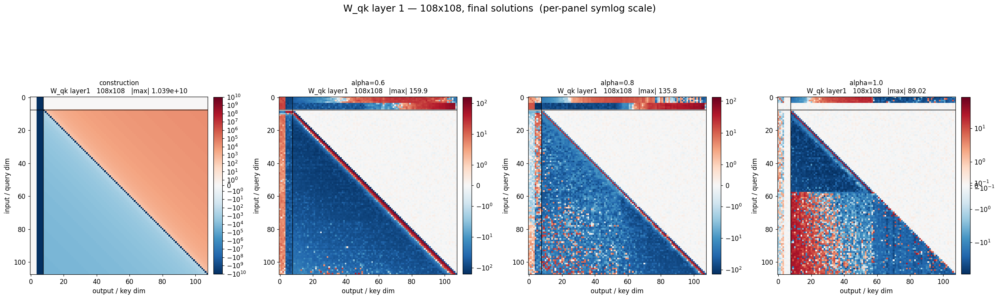

In [4]:
fig, axes = plt.subplots(1, 1 + len(THRS), figsize=(8.0 * (1 + len(THRS)) / 1.35, 8.5))
for ax, (nm, M) in zip(np.atleast_1d(axes),
                       [('construction', PROD['W_qk layer1'])] +
                       [(f'alpha={t}', QK[t][0]) for t in THRS]):
    im = show(ax, M, f'{nm}\nW_qk layer1')
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.03)
fig.suptitle('W_qk layer 1 — 108x108, final solutions  (per-panel symlog scale)', fontsize=16)
fig.tight_layout()
fig.savefig(os.path.join(FIGDIR, 'final_wqk1.png'), bbox_inches='tight')
plt.show()


## 3. $W_{qk}$ layer 2 — the induction match

48 non-zeros out of 46,656 in the construction (0.10%); the learned matrices are fully dense.
Each is plotted at full size so individual cells are visible.


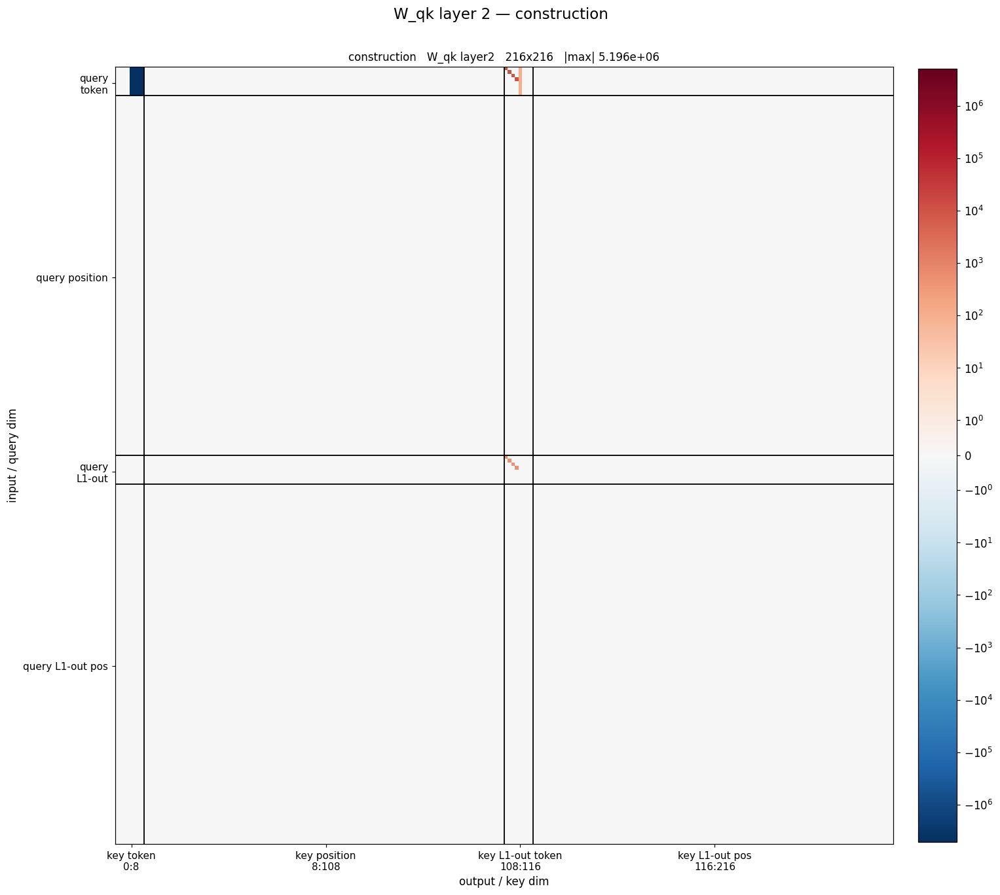

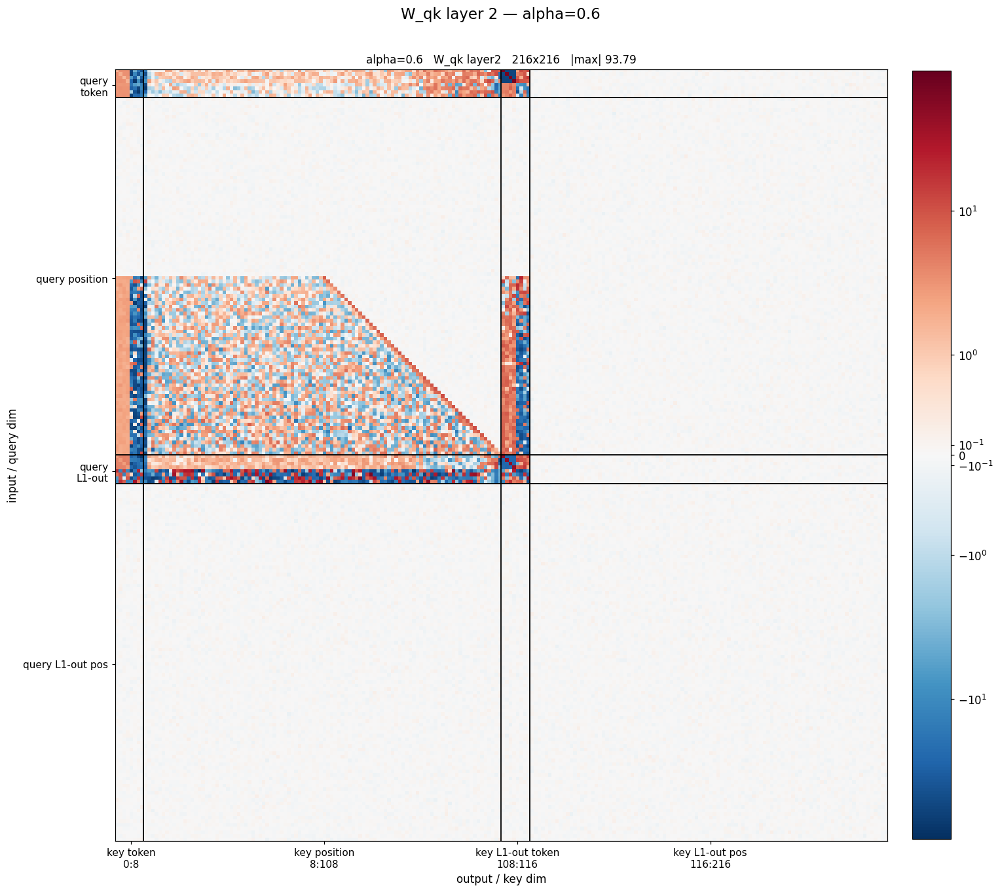

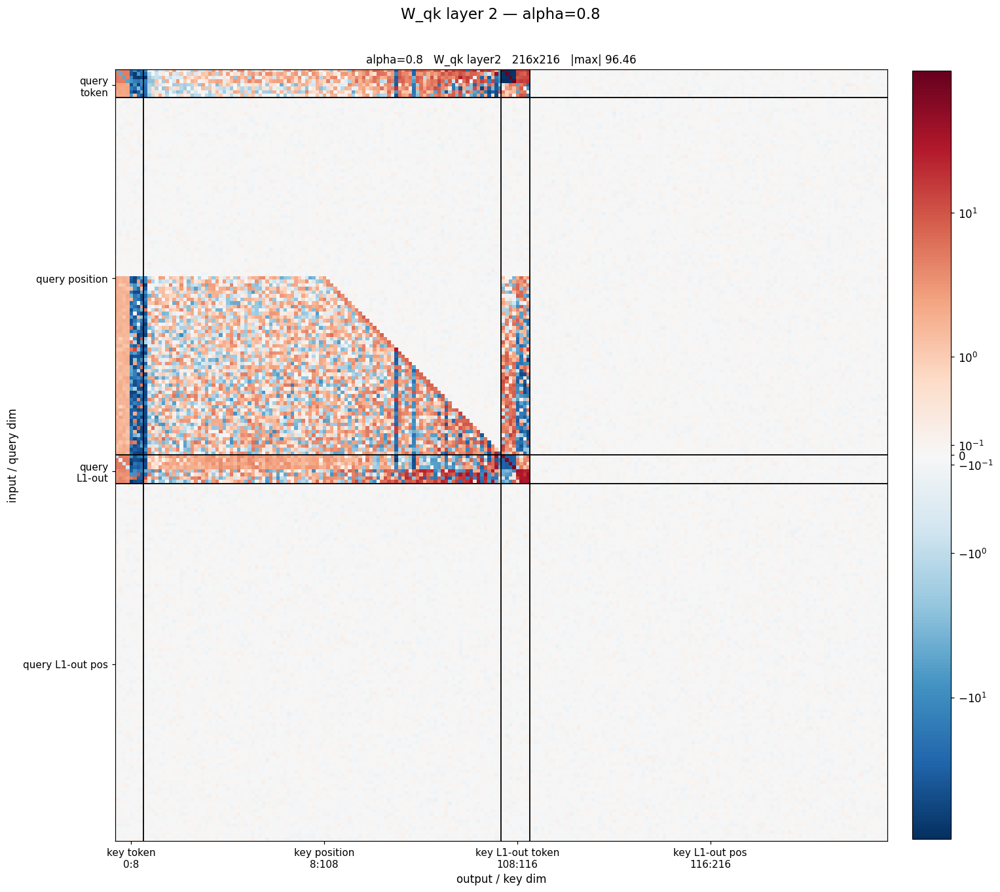

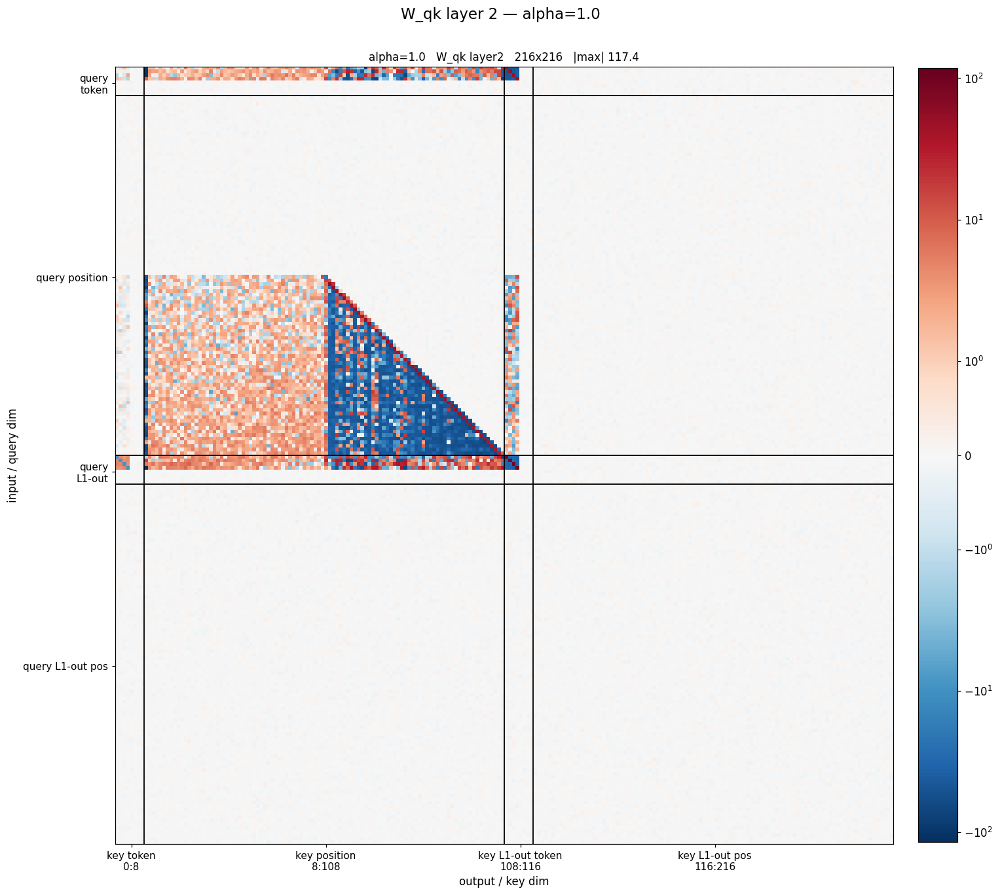

In [5]:
for nm, M in [('construction', PROD['W_qk layer2'])] + \
             [(f'alpha={t}', QK[t][1]) for t in THRS]:
    fig, ax = plt.subplots(figsize=(14, 13))
    im = show(ax, M, f'{nm}   W_qk layer2', lw=1.2)
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.03)
    ax.set_xticks([V // 2, V + T // 2, D + V // 2, D + V + T // 2])
    ax.set_xticklabels(['key token\n0:8', 'key position\n8:108',
                        'key L1-out token\n108:116', 'key L1-out pos\n116:216'], fontsize=10)
    ax.set_yticks([V // 2, V + T // 2, D + V // 2, D + V + T // 2])
    ax.set_yticklabels(['query\ntoken', 'query position', 'query\nL1-out',
                        'query L1-out pos'], fontsize=10)
    fig.suptitle(f'W_qk layer 2 — {nm}', fontsize=15)
    fig.tight_layout()
    fig.savefig(os.path.join(FIGDIR, f'final_wqk2_{nm.replace("=", "")}.png'),
                bbox_inches='tight')
    plt.show()


## 4. Annotated close-ups — every cell value printed

The same four blocks as the folder-14 notebook, construction in the left column. The one that
decides whether the head works is **L2 own token $\times$ key predecessor**: its $4\times4$
diagonal has to dominate its own off-diagonal.


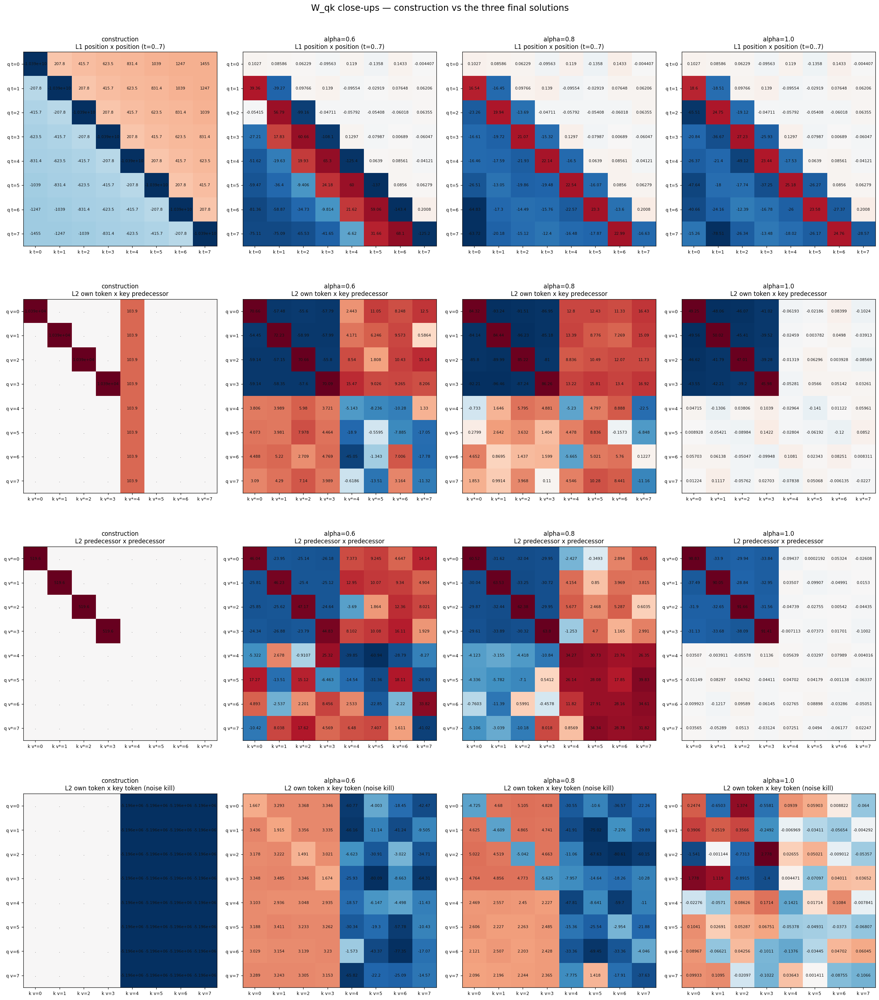

 alpha  induction diag/off   L1 ramp corr vs constr   cos Wqk2 vs constr
   0.6                1.23                   0.5785                0.169
   0.8                0.95                   0.4394                0.181
   1.0                1.10                   0.1458                0.000


In [6]:
BLOCKS = [('L1 position x position (t=0..7)', 0, V, V + 8, V, V + 8,
           [f'q t={i}' for i in range(8)], [f'k t={i}' for i in range(8)]),
          ('L2 own token x key predecessor', 1, 0, V, D, D + V,
           [f'q v={i}' for i in range(V)], [f'k v*={i}' for i in range(V)]),
          ('L2 predecessor x predecessor', 1, D, D + V, D, D + V,
           [f'q v*={i}' for i in range(V)], [f'k v*={i}' for i in range(V)]),
          ('L2 own token x key token (noise kill)', 1, 0, V, 0, V,
           [f'q v={i}' for i in range(V)], [f'k v={i}' for i in range(V)])]

ncol = 1 + len(THRS)
fig, axes = plt.subplots(len(BLOCKS), ncol, figsize=(5.6 * ncol, 6.4 * len(BLOCKS)))
for r, (title, li, r0, r1, c0, c1, rlab, clab) in enumerate(BLOCKS):
    key = 'W_qk layer1' if li == 0 else 'W_qk layer2'
    panels = [('construction', PROD[key])] + [(f'alpha={t}', QK[t][li]) for t in THRS]
    for c, (nm, M) in enumerate(panels):
        annot(axes[r][c], M, r0, r1, c0, c1, f'{nm}\n{title}', rlab=rlab, clab=clab, fs=7)
fig.suptitle('W_qk close-ups — construction vs the three final solutions', fontsize=16, y=0.999)
fig.tight_layout()
fig.savefig(os.path.join(FIGDIR, 'final_closeups.png'), bbox_inches='tight')
plt.show()

print(f'{"alpha":>6s} {"induction diag/off":>19s} {"L1 ramp corr vs constr":>24s} '
      f'{"cos Wqk2 vs constr":>20s}')
cramp = PROD['W_qk layer1'][V:, V:].numpy()
mask = ~np.eye(T, dtype=bool)
for t in THRS:
    b = QK[t][1][:V, D:D + V].numpy()
    lr = QK[t][0][V:, V:].numpy()
    r = float(np.corrcoef(lr[mask], cramp[mask])[0, 1])
    print(f'{t:6.1f} {diag_off(b):19.2f} {r:24.4f} {cos(QK[t][1], PROD["W_qk layer2"]):20.3f}')


## 5. The trajectory — curves

Every curve below starts at **epoch 0 = the random initialization**, measured before the first
optimizer step, exactly as the training script records it. `induction_diag_off` is the
$4\times4$ diagonal-to-off-diagonal ratio of the L2 induction block — the construction's value is
$\infty$, so any climb away from ~1 is GD building the match.


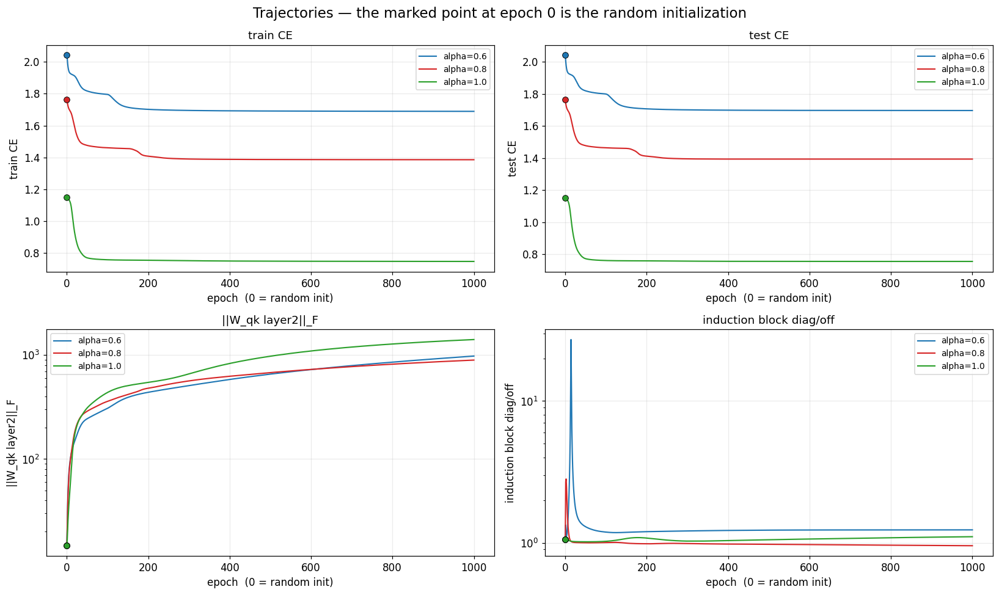

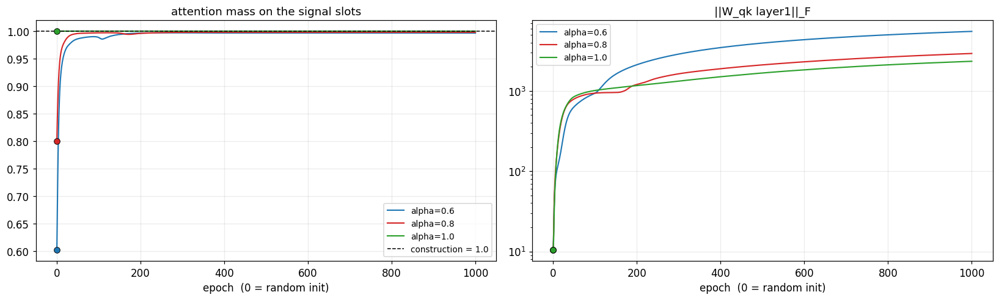

In [7]:
COLORS = {t: c for t, c in zip(THRS, ['#1f77b4', '#d62728', '#2ca02c', '#9467bd'])}

fig, axes = plt.subplots(2, 2, figsize=(15, 9))
panels = [('train_loss', 'train CE', 'linear'), ('test_loss', 'test CE', 'linear'),
          ('wqk2_fro', '||W_qk layer2||_F', 'log'),
          ('induction_diag_off', 'induction block diag/off', 'log')]
for ax, (key, lab, ys) in zip(axes.ravel(), panels):
    for t in THRS:
        h = MET[t]['history']
        ax.plot(h['epoch'], h[key], color=COLORS[t], lw=1.4, label=f'alpha={t}')
        ax.scatter([h['epoch'][0]], [h[key][0]], color=COLORS[t], s=40, zorder=5,
                   edgecolor='k', linewidth=0.6)
    ax.set_yscale(ys); ax.set_xlabel('epoch  (0 = random init)'); ax.set_ylabel(lab)
    ax.set_title(lab); ax.grid(alpha=0.25); ax.legend(fontsize=9)
fig.suptitle('Trajectories — the marked point at epoch 0 is the random initialization',
             fontsize=15)
fig.tight_layout()
fig.savefig(os.path.join(FIGDIR, 'trajectory_curves.png'), bbox_inches='tight')
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
for ax, (key, lab) in zip(axes, [('signal_mass', 'attention mass on the signal slots'),
                                 ('wqk1_fro', '||W_qk layer1||_F')]):
    for t in THRS:
        h = MET[t]['history']
        ax.plot(h['epoch'], h[key], color=COLORS[t], lw=1.4, label=f'alpha={t}')
        ax.scatter([h['epoch'][0]], [h[key][0]], color=COLORS[t], s=40, zorder=5,
                   edgecolor='k', linewidth=0.6)
    if key == 'signal_mass':
        ax.axhline(1.0, color='k', ls='--', lw=1, label='construction = 1.0')
    else:
        ax.set_yscale('log')
    ax.set_xlabel('epoch  (0 = random init)'); ax.set_title(lab)
    ax.grid(alpha=0.25); ax.legend(fontsize=9)
fig.tight_layout()
fig.savefig(os.path.join(FIGDIR, 'trajectory_curves2.png'), bbox_inches='tight')
plt.show()


## 6. The trajectory — snapshots

The `.npy` files are opened with `mmap_mode='r'`, so nothing is pulled into memory that isn't
plotted. `SNAP[t][i][e]` is $W_{qk}$ of layer $i{+}1$ at row $e$, row 0 being the initialization.


alpha=0.6: 1001 rows, epochs [0, 1, 2, 3] ... [999, 1000]   shapes (1001, 108, 108) (1001, 216, 216)
alpha=0.8: 1001 rows, epochs [0, 1, 2, 3] ... [999, 1000]   shapes (1001, 108, 108) (1001, 216, 216)
alpha=1.0: 1001 rows, epochs [0, 1, 2, 3] ... [999, 1000]   shapes (1001, 108, 108) (1001, 216, 216)


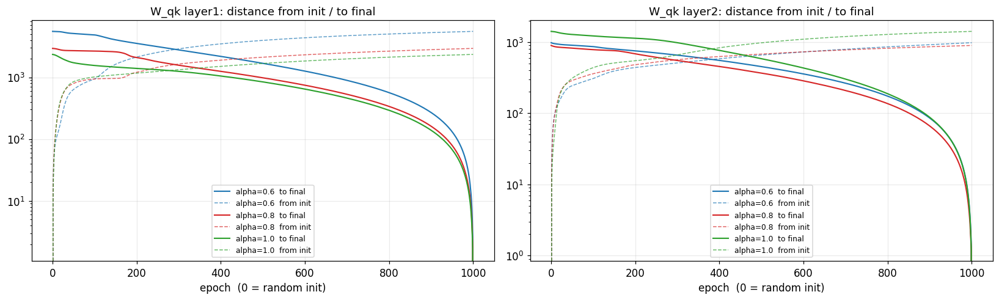

In [8]:
SNAP, SMETA = {}, {}
for t in THRS:
    SMETA[t] = json.load(open(os.path.join(ADIR, f'snapmeta_x_{t}.json')))
    n = SMETA[t]['rows_written']
    SNAP[t] = [np.load(os.path.join(ADIR, f'wqk{i}_x_{t}.npy'), mmap_mode='r')[:n]
               for i in (1, 2)]
    print(f'alpha={t}: {n} rows, epochs {SMETA[t]["epochs"][:4]} ... '
          f'{SMETA[t]["epochs"][-2:]}   shapes {SNAP[t][0].shape} {SNAP[t][1].shape}')

def frame_epochs(t, k=8):
    '''k epochs spaced logarithmically -- the motion is nearly all in the first hundred.'''
    n = SNAP[t][0].shape[0]
    idx = np.unique(np.round(np.geomspace(1, n, k)).astype(int) - 1)
    return [(i, SMETA[t]['epochs'][i]) for i in idx]

# distance travelled: ||W(e) - W(final)||_F  and  ||W(e) - W(0)||_F
fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
for ax, li in zip(axes, [0, 1]):
    for t in THRS:
        A = SNAP[t][li]
        fin = np.asarray(A[-1], dtype=np.float64)
        ini = np.asarray(A[0], dtype=np.float64)
        ep = SMETA[t]['epochs']
        to_fin = [np.linalg.norm(np.asarray(A[e], dtype=np.float64) - fin)
                  for e in range(A.shape[0])]
        from_ini = [np.linalg.norm(np.asarray(A[e], dtype=np.float64) - ini)
                    for e in range(A.shape[0])]
        ax.plot(ep, to_fin, color=COLORS[t], lw=1.4, label=f'alpha={t}  to final')
        ax.plot(ep, from_ini, color=COLORS[t], lw=1.0, ls='--', alpha=0.7,
                label=f'alpha={t}  from init')
    ax.set_yscale('log'); ax.set_xlabel('epoch  (0 = random init)')
    ax.set_title(f'W_qk layer{li + 1}: distance from init / to final')
    ax.grid(alpha=0.25); ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(os.path.join(FIGDIR, 'trajectory_distance.png'), bbox_inches='tight')
plt.show()


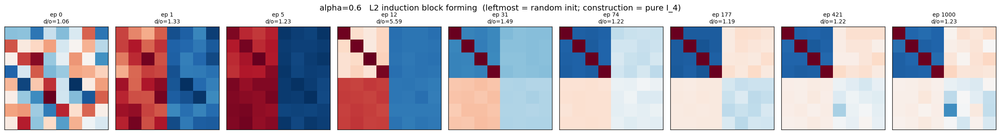

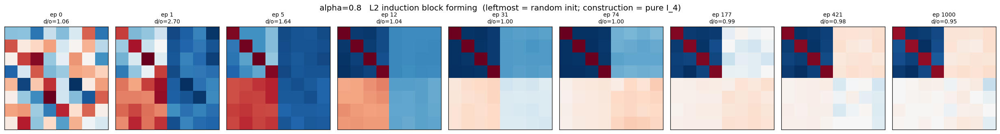

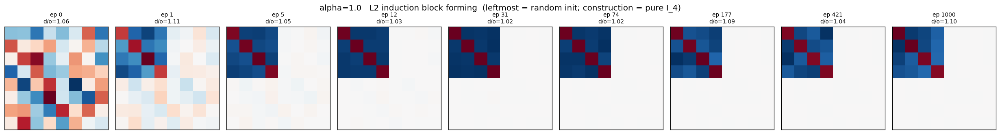

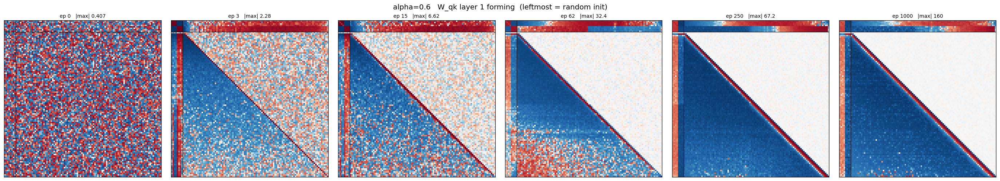

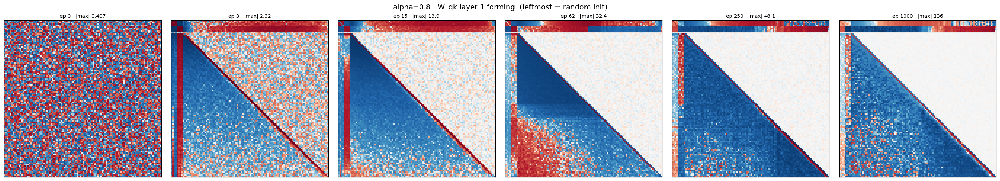

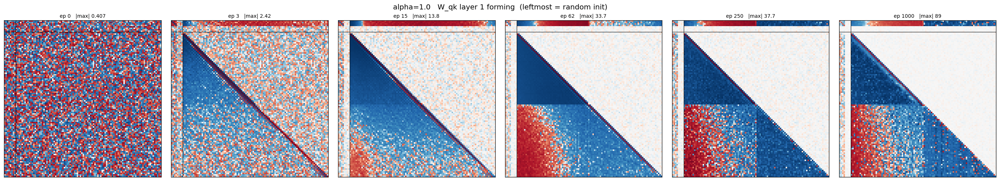

In [9]:
# filmstrip: the L2 induction block (own token x key predecessor) as it forms
for t in THRS:
    fr = frame_epochs(t, 9)
    fig, axes = plt.subplots(1, len(fr), figsize=(2.5 * len(fr), 3.1))
    for ax, (i, e) in zip(np.atleast_1d(axes), fr):
        b = np.asarray(SNAP[t][1][i][:V, D:D + V])
        v = np.abs(b).max() or 1.0
        ax.imshow(b, cmap='RdBu_r', vmin=-v, vmax=v, interpolation='nearest')
        ax.set_title(f'ep {e}\nd/o={diag_off(b):.2f}', fontsize=9)
        ax.set_xticks([]); ax.set_yticks([])
    fig.suptitle(f'alpha={t}   L2 induction block forming  '
                 '(leftmost = random init; construction = pure I_4)', fontsize=13)
    fig.tight_layout()
    fig.savefig(os.path.join(FIGDIR, f'filmstrip_induction_a{t}.png'), bbox_inches='tight')
    plt.show()

# filmstrip: W_qk layer 1, full matrix
for t in THRS:
    fr = frame_epochs(t, 6)
    fig, axes = plt.subplots(1, len(fr), figsize=(4.2 * len(fr), 4.6))
    for ax, (i, e) in zip(np.atleast_1d(axes), fr):
        A = np.asarray(SNAP[t][0][i])
        v = np.abs(A).max() or 1.0
        ax.imshow(A, cmap='RdBu_r', interpolation='nearest',
                  norm=SymLogNorm(linthresh=min(1.0, v / 100), linscale=0.6,
                                  vmin=-v, vmax=v, base=10))
        ax.axhline(V - .5, color='k', lw=0.7); ax.axvline(V - .5, color='k', lw=0.7)
        ax.set_title(f'ep {e}   |max| {v:.3g}', fontsize=9)
        ax.set_xticks([]); ax.set_yticks([])
    fig.suptitle(f'alpha={t}   W_qk layer 1 forming  (leftmost = random init)', fontsize=13)
    fig.tight_layout()
    fig.savefig(os.path.join(FIGDIR, f'filmstrip_wqk1_a{t}.png'), bbox_inches='tight')
    plt.show()


## 7. The animation

One mp4 per threshold, three panels: $W_{qk}$ layer 1, $W_{qk}$ layer 2, and the L2 induction
block, with the CE curve's current epoch marked. Colour scales are **per frame** (the amplitude
grows by orders of magnitude, so a fixed scale would show a black screen then a flash).

Set `ANIM_STRIDE` to thin the frames — 1000 frames at 25 fps is a 40 s clip and takes a few
minutes to encode. mp4 needs `ffmpeg` on the path; the fallback writes an animated gif.


In [10]:
import matplotlib.animation as animation

ANIM_THR    = 0.8
ANIM_STRIDE = 1           # every 5th snapshot -> 200 frames
FPS         = 50

A1, A2 = SNAP[ANIM_THR]
eps = SMETA[ANIM_THR]['epochs']
idx = list(range(0, A1.shape[0], ANIM_STRIDE))
if idx[-1] != A1.shape[0] - 1:
    idx.append(A1.shape[0] - 1)
h = MET[ANIM_THR]['history']

fig = plt.figure(figsize=(16, 5.2))
gs = fig.add_gridspec(1, 4, width_ratios=[1, 1, 0.75, 1.1])
ax1, ax2, ax3, ax4 = [fig.add_subplot(gs[0, i]) for i in range(4)]

def draw(fi):
    e_i = idx[fi]; e = eps[e_i]
    for ax in (ax1, ax2, ax3):
        ax.clear(); ax.set_xticks([]); ax.set_yticks([])
    for ax, A, ttl in ((ax1, np.asarray(A1[e_i]), 'W_qk layer 1  108x108'),
                       (ax2, np.asarray(A2[e_i]), 'W_qk layer 2  216x216')):
        v = np.abs(A).max() or 1.0
        ax.imshow(A, cmap='RdBu_r', interpolation='nearest',
                  norm=SymLogNorm(linthresh=min(1.0, v / 100), linscale=0.6,
                                  vmin=-v, vmax=v, base=10))
        ax.set_title(f'{ttl}\n|max| {v:.4g}', fontsize=10)
    b = np.asarray(A2[e_i][:V, D:D + V])
    v = np.abs(b).max() or 1.0
    ax3.imshow(b, cmap='RdBu_r', vmin=-v, vmax=v, interpolation='nearest')
    ax3.set_title(f'L2 induction block\ndiag/off {diag_off(b):.2f}', fontsize=10)
    ax4.clear()
    ax4.plot(h['epoch'], h['train_loss'], color='#1f77b4', lw=1.2, label='train')
    ax4.plot(h['epoch'], h['test_loss'], color='#d62728', lw=1.2, label='test')
    ax4.axvline(e, color='k', lw=1.0)
    ax4.set_xlabel('epoch  (0 = random init)'); ax4.set_ylabel('CE')
    ax4.grid(alpha=0.25); ax4.legend(fontsize=8)
    ax4.set_title(f'CE   epoch {e}', fontsize=10)
    fig.suptitle(f'W_qk evolution, alpha={ANIM_THR}  —  epoch {e} '
                 f'{"(random initialization)" if e == 0 else ""}', fontsize=14)

anim = animation.FuncAnimation(fig, draw, frames=len(idx), interval=1000 // FPS, blit=False)
out = os.path.join(FIGDIR, f'wqk_evolution_a{ANIM_THR}.mp4')
try:
    anim.save(out, writer=animation.FFMpegWriter(fps=FPS, bitrate=3000))
except Exception as err:
    print(f'ffmpeg unavailable ({type(err).__name__}: {err}) -- writing a gif instead')
    out = out.replace('.mp4', '.gif')
    anim.save(out, writer=animation.PillowWriter(fps=FPS))
plt.close(fig)
print(f'{len(idx)} frames -> {out}')

from IPython.display import Video, Image, display
display(Video(out, embed=True, width=1100) if out.endswith('.mp4') else Image(out))


1001 frames -> artifacts/figures/wqk_evolution_a0.8.mp4


## 8. The first epochs, full size

Section 7's clip strides across the whole run, which compresses the part that matters most —
what the two matrices do in the first few passes over the data, starting from the random
initialization. This one plays **every** epoch of the opening window at full panel size:
$W_{qk}$ layer 1 (108x108) on the left, $W_{qk}$ layer 2 (216x216) on the right.

* `EARLY_N` — how many epochs after the init to include. Frame 0 is always the initialization.
* `EARLY_SCALE` — `'fixed'` shares one colour scale across the whole window, so **growth in
  amplitude shows up as the picture getting louder**; `'frame'` rescales every frame, which hides
  growth but reveals the emerging *pattern* earlier. Fixed is the default, because at init the
  question is how fast structure lifts out of the noise.

One mp4 per threshold.

In [11]:
import matplotlib.animation as animation
from IPython.display import Video, Image, display

EARLY_N     = 40          # epochs after the init; frame 0 is the init itself
EARLY_SCALE = 'fixed'     # 'fixed' -> one scale for the window | 'frame' -> per-frame
EARLY_FPS   = 6
EARLY_DPI   = 110

def early_animation(t):
    A1, A2 = SNAP[t]
    n = min(EARLY_N + 1, A1.shape[0])
    eps = SMETA[t]['epochs'][:n]
    W1 = np.asarray(A1[:n], dtype=np.float32)
    W2 = np.asarray(A2[:n], dtype=np.float32)
    h = MET[t]['history']
    ce = {e: (h['train_loss'][e], h['test_loss'][e]) for e in eps if e < len(h['train_loss'])}
    v1f = float(np.abs(W1).max()) or 1.0
    v2f = float(np.abs(W2).max()) or 1.0

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(21, 10.5))

    def nrm(v):
        return SymLogNorm(linthresh=min(1.0, v / 100), linscale=0.6, vmin=-v, vmax=v, base=10)

    def draw(fi):
        e = eps[fi]
        for ax, A, vfix, ttl, bl in ((ax1, W1[fi], v1f, 'W_qk layer 1   108x108', [V]),
                                     (ax2, W2[fi], v2f, 'W_qk layer 2   216x216',
                                      [V, D, D + V])):
            ax.clear()
            v = vfix if EARLY_SCALE == 'fixed' else (float(np.abs(A).max()) or 1.0)
            ax.imshow(A, cmap='RdBu_r', interpolation='nearest', norm=nrm(v))
            for b in bl:
                ax.axhline(b - .5, color='k', lw=0.8); ax.axvline(b - .5, color='k', lw=0.8)
            ax.set_xticks([]); ax.set_yticks([])
            ax.set_title(f'{ttl}\n|max| {np.abs(A).max():.4g}   '
                         f'||.||_F {np.linalg.norm(A):.4g}', fontsize=13)
        b = W2[fi][:V, D:D + V]
        tr, te = ce.get(e, (float('nan'), float('nan')))
        head = 'random initialization' if e == 0 else f'epoch {e}'
        fig.suptitle(f'alpha={t}   W_qk at {head}   —   train CE {tr:.4f}   test CE {te:.4f}   '
                     f'induction diag/off {diag_off(b):.2f}   '
                     f'[{EARLY_SCALE} colour scale]', fontsize=16)

    anim = animation.FuncAnimation(fig, draw, frames=len(eps),
                                   interval=1000 // EARLY_FPS, blit=False)
    out = os.path.join(FIGDIR, f'wqk_init_a{t}.mp4')
    try:
        anim.save(out, writer=animation.FFMpegWriter(fps=EARLY_FPS, bitrate=6000), dpi=EARLY_DPI)
    except Exception as err:
        print(f'  ffmpeg unavailable ({type(err).__name__}: {err}) -- gif instead')
        out = out.replace('.mp4', '.gif')
        anim.save(out, writer=animation.PillowWriter(fps=EARLY_FPS), dpi=EARLY_DPI)
    plt.close(fig)
    print(f'alpha={t}: {len(eps)} frames (epochs {eps[0]}..{eps[-1]}) -> {out}')
    return out

for t in THRS:
    o = early_animation(t)
    display(Video(o, embed=True, width=1200) if o.endswith('.mp4') else Image(o))

alpha=0.6: 41 frames (epochs 0..40) -> artifacts/figures/wqk_init_a0.6.mp4


alpha=0.8: 41 frames (epochs 0..40) -> artifacts/figures/wqk_init_a0.8.mp4


alpha=1.0: 41 frames (epochs 0..40) -> artifacts/figures/wqk_init_a1.0.mp4


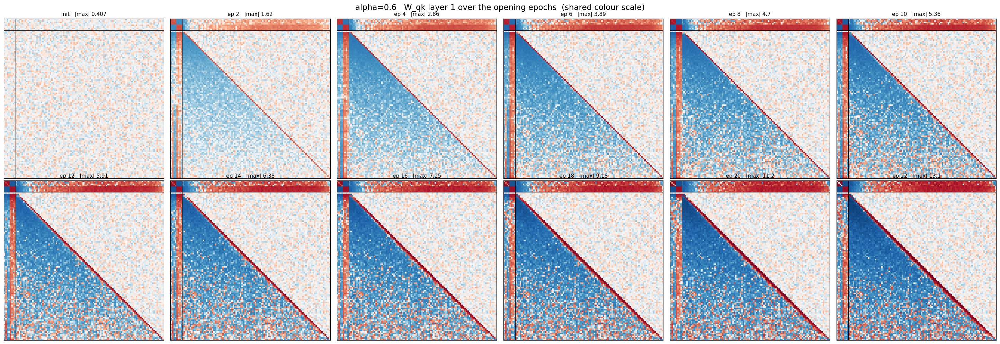

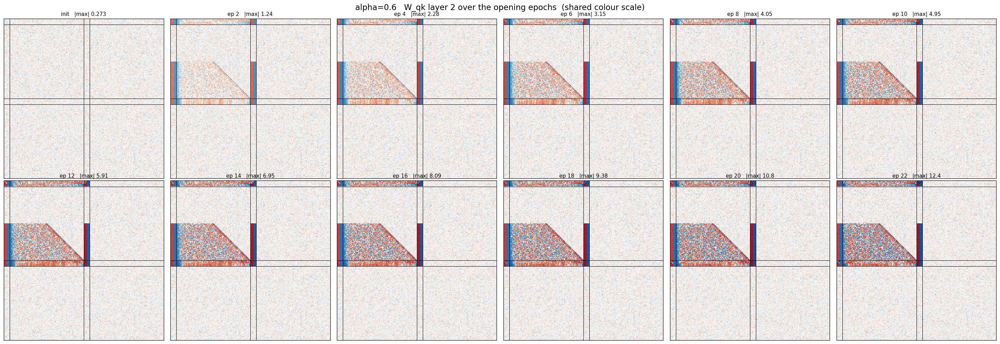

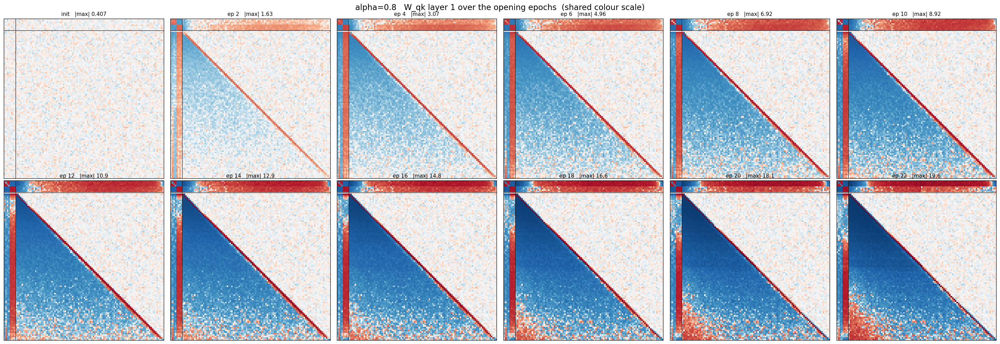

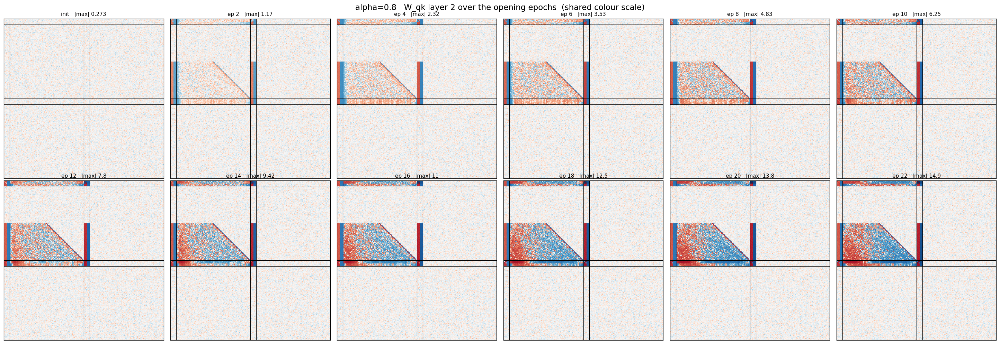

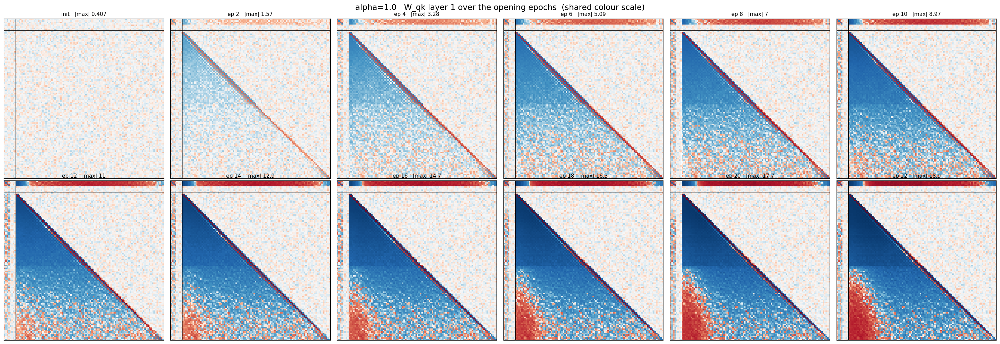

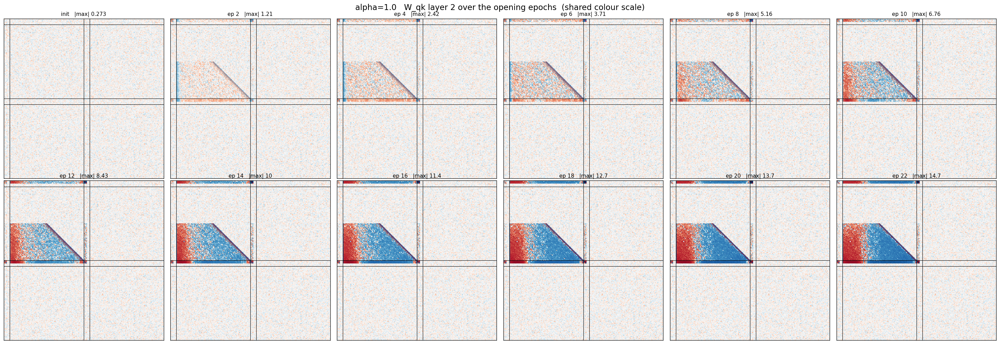

In [12]:
# the same opening window as a still grid -- easier to scrub by eye than a clip
GRID_N, GRID_STEP = 12, 2          # first GRID_N*GRID_STEP epochs, every GRID_STEP-th

for t in THRS:
    idx = list(range(0, min(GRID_N * GRID_STEP, SNAP[t][0].shape[0]), GRID_STEP))
    for li, (nm, blocks) in enumerate([('W_qk layer 1', [V]), ('W_qk layer 2', [V, D, D + V])]):
        A = np.asarray(SNAP[t][li][idx], dtype=np.float32)
        vf = float(np.abs(A).max()) or 1.0
        ncol = 6
        nrow = int(np.ceil(len(idx) / ncol))
        fig, axes = plt.subplots(nrow, ncol, figsize=(4.4 * ncol, 4.6 * nrow))
        flat = np.atleast_1d(axes).ravel()
        for k in range(len(idx)):
            ax = flat[k]
            ax.imshow(A[k], cmap='RdBu_r', interpolation='nearest',
                      norm=SymLogNorm(linthresh=min(1.0, vf / 100), linscale=0.6,
                                      vmin=-vf, vmax=vf, base=10))
            for b in blocks:
                ax.axhline(b - .5, color='k', lw=0.7); ax.axvline(b - .5, color='k', lw=0.7)
            e = SMETA[t]['epochs'][idx[k]]
            ax.set_title(f'{"init" if e == 0 else f"ep {e}"}   |max| {np.abs(A[k]).max():.3g}',
                         fontsize=10)
            ax.set_xticks([]); ax.set_yticks([])
        for ax in flat[len(idx):]:
            ax.axis('off')
        fig.suptitle(f'alpha={t}   {nm} over the opening epochs  (shared colour scale)',
                     fontsize=15)
        fig.tight_layout()
        fig.savefig(os.path.join(FIGDIR, f'init_grid_wqk{li + 1}_a{t}.png'), bbox_inches='tight')
        plt.show()

---

# 9. The gradients

**The gradients were never recorded during training** — the script stores parameters only. So the
cell below **recomputes** them: it loads $W_{qk}(e)$ from each snapshot row back into the model and
runs one full-batch forward/backward over the 25,000 training sequences, giving the exact

$$g_i(e) \;=\; \nabla_{W_{qk}^{Li}}\, \mathcal{L}_{\text{train}}\big(W(e)\big),$$

for every epoch $e$, row 0 included (the gradient at the random initialization). ~0.3 s per
snapshot, so ~15 min for all 3 thresholds; the result is cached to
`artifacts/<cell>/grad{1,2}_x_{alpha}.npy` and the cell is a no-op on re-runs.

### Two different things, both worth plotting

* $g(e)$ — the **gradient**, what the loss surface asks for at that point.
* $\Delta W(e) = W(e) - W(e-1)$ — the **update actually applied**. Under Adam these are *not*
  proportional: Adam divides by a running RMS, so $\Delta W$ is roughly sign-like and far more
  uniform in magnitude than $g$. Both are plotted, because the difference between them is the
  optimizer's contribution.

$\Delta W$ costs nothing (it comes straight from the snapshots); only $g$ needs the recompute.

In [13]:
import torch.nn.functional as F

GRAD_DEVICE = 'cuda:3'
GRAD_STRIDE = 1          # snapshots between gradient evaluations; 1 = every epoch
GRAD_NSEQ   = None       # None = the full training set (exact gradient)
GRAD_BATCH  = 512

def grad_paths(t):
    return (os.path.join(ADIR, f'grad1_x_{t}.npy'), os.path.join(ADIR, f'grad2_x_{t}.npy'),
            os.path.join(ADIR, f'gradmeta_x_{t}.json'))

def compute_grads(t, device=GRAD_DEVICE):
    '''Recompute dL/dW_qk at every snapshot row. Cached; returns (rows, epochs).'''
    g1p, g2p, mp = grad_paths(t)
    rows = list(range(0, SNAP[t][0].shape[0], GRAD_STRIDE))
    if os.path.exists(mp):
        meta = json.load(open(mp))
        if meta.get('rows') == len(rows) and meta.get('stride') == GRAD_STRIDE:
            print(f'alpha={t}: cached ({meta["rows"]} rows) -> {os.path.basename(g1p)}')
            return meta
    dev = torch.device(device if torch.cuda.is_available() else 'cpu')
    blob = EV.load_data('train', t)
    x, y = blob['x'], blob['y']
    n = x.shape[0] if GRAD_NSEQ is None else min(GRAD_NSEQ, x.shape[0])
    ts, te = EV.CFG['token_start'], EV.CFG['seq_len']
    ntok = n * (te - ts)

    m = EV.QKOnlyTransformer(V, T, D, VS, t).to(dev)
    ps = EV.install_fixed(m)
    m.eval()

    A1, A2 = SNAP[t]
    G1 = np.lib.format.open_memmap(g1p, mode='w+', dtype=np.float32,
                                   shape=(len(rows),) + A1.shape[1:])
    G2 = np.lib.format.open_memmap(g2p, mode='w+', dtype=np.float32,
                                   shape=(len(rows),) + A2.shape[1:])
    t0 = time.time()
    for k, r in enumerate(rows):
        with torch.no_grad():
            m.layer1.W_qk.copy_(torch.from_numpy(np.asarray(A1[r])).to(dev))
            m.layer2.W_qk.copy_(torch.from_numpy(np.asarray(A2[r])).to(dev))
        for pp in ps:
            pp.grad = None
        for i in range(0, n, GRAD_BATCH):
            xb = x[i:i + GRAD_BATCH].to(dev)
            yb = y[i:i + GRAD_BATCH, ts:te].to(dev)
            loss = F.cross_entropy(m(xb)[:, ts:te].reshape(-1, V), yb.reshape(-1),
                                   reduction='sum') / ntok
            loss.backward()
        G1[k] = ps[0].grad.detach().cpu().numpy()
        G2[k] = ps[1].grad.detach().cpu().numpy()
        if k % 100 == 0:
            G1.flush(); G2.flush()
            el = time.time() - t0
            print(f'  alpha={t}  row {k}/{len(rows)}  {el:.0f}s elapsed  '
                  f'ETA {el / max(k, 1) * (len(rows) - k):.0f}s', flush=True)
    G1.flush(); G2.flush()
    meta = {'threshold': float(t), 'rows': len(rows), 'stride': GRAD_STRIDE,
            'epochs': [SMETA[t]['epochs'][r] for r in rows], 'n_seq': n,
            'full_batch': GRAD_NSEQ is None, 'time_s': round(time.time() - t0, 1),
            'row0': 'gradient at the random init'}
    json.dump(meta, open(mp, 'w'), indent=2)
    print(f'alpha={t}: {len(rows)} rows in {meta["time_s"]/60:.1f}m -> {g1p}')
    return meta

import time
GRAD, GMETA = {}, {}
for t in THRS:
    GMETA[t] = compute_grads(t)
    g1p, g2p, _ = grad_paths(t)
    GRAD[t] = [np.load(g1p, mmap_mode='r'), np.load(g2p, mmap_mode='r')]
    print(f'   shapes {GRAD[t][0].shape} {GRAD[t][1].shape}')

/home/hariguru/.cache/ashu_tmp/ipykernel_1959382/703026647.py:40: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at ../torch/csrc/utils/tensor_numpy.cpp:206.)
  m.layer1.W_qk.copy_(torch.from_numpy(np.asarray(A1[r])).to(dev))


  alpha=0.6  row 0/1001  1s elapsed  ETA 915s


  alpha=0.6  row 100/1001  28s elapsed  ETA 251s


  alpha=0.6  row 200/1001  55s elapsed  ETA 220s


  alpha=0.6  row 300/1001  82s elapsed  ETA 191s


  alpha=0.6  row 400/1001  109s elapsed  ETA 163s


... (27 outputs left out)

  alpha=1.0  row 800/1001  413s elapsed  ETA 104s


  alpha=1.0  row 900/1001  474s elapsed  ETA 53s


  alpha=1.0  row 1000/1001  535s elapsed  ETA 1s


alpha=1.0: 1001 rows in 8.9m -> artifacts/wqkevo_opt-adam_lr-0.005_b-256_init-normal_ep-1000/grad1_x_1.0.npy
   shapes (1001, 108, 108) (1001, 216, 216)


## 9.1 Gradient magnitude over the run

$\|g\|_F$ for both layers, against $\|\Delta W\|_F$ for the same epoch. If Adam is doing its job
the two curves diverge: the gradient can fall by orders of magnitude while the step size stays
roughly flat.

The right-hand panel is $\cos\big(g(e),\,g(e-1)\big)$ — how much consecutive gradients agree.
Near $+1$ means a consistent descent direction (the parameters are sliding down a valley);
near $0$ or oscillating means successive full-batch gradients point in unrelated directions.

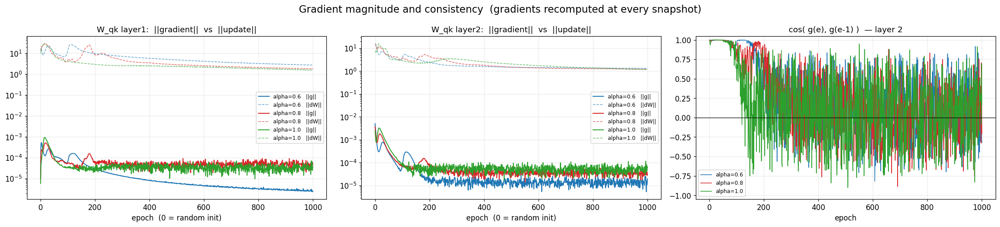

 alpha     ep       ||g1||       ||g2||      ||dW1||      ||dW2||
   0.6      0    1.064e-05     0.005105          nan          nan
   0.6      1     0.000336     0.003865        13.35        16.31
   0.6      5    0.0004024     0.001087        12.08        11.01
   0.6     20    0.0001474    0.0004632        16.96        6.045
   0.6     40    0.0001748    0.0004899        15.75        5.616
   0.6    100     6.71e-05    6.939e-05        13.27          3.7
   0.6    500    5.891e-06    1.598e-05         4.87        1.497
   0.6   1000    2.542e-06    2.001e-05        2.693        1.329

   0.8      0    1.032e-05     0.003785          nan          nan
   0.8      1    0.0001274     0.002826        12.96        14.83
   0.8      5    0.0002255    0.0009231        20.21        11.24
   0.8     20    0.0005048     0.001742        27.78        10.51
   0.8     40    0.0001225     0.000513        10.67        5.122
   0.8    100    5.382e-05    7.241e-05        4.508        3.627
   0.8   

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(21, 4.8))
for t in THRS:
    ep = GMETA[t]['epochs']
    for li, ax in enumerate(axes[:2]):
        G = GRAD[t][li]
        gn = np.linalg.norm(np.asarray(G, dtype=np.float32).reshape(G.shape[0], -1), axis=1)
        ax.plot(ep, gn, color=COLORS[t], lw=1.3, label=f'alpha={t}   ||g||')
        A = SNAP[t][li]
        W = np.asarray(A[::GRAD_STRIDE], dtype=np.float32).reshape(-1, A.shape[1] * A.shape[2])
        dW = np.linalg.norm(np.diff(W, axis=0), axis=1)
        ax.plot(ep[1:], dW, color=COLORS[t], lw=1.0, ls='--', alpha=0.65,
                label=f'alpha={t}   ||dW||')
    G = GRAD[t][1]
    g = np.asarray(G, dtype=np.float32).reshape(G.shape[0], -1)
    nrm_ = np.linalg.norm(g, axis=1, keepdims=True)
    u = g / np.maximum(nrm_, 1e-30)
    axes[2].plot(ep[1:], (u[1:] * u[:-1]).sum(1), color=COLORS[t], lw=1.0, label=f'alpha={t}')

for li, ax in enumerate(axes[:2]):
    ax.set_yscale('log'); ax.set_xlabel('epoch  (0 = random init)')
    ax.set_title(f'W_qk layer{li + 1}:  ||gradient||  vs  ||update||')
    ax.grid(alpha=0.25); ax.legend(fontsize=8)
axes[2].axhline(0, color='k', lw=0.8)
axes[2].set_xlabel('epoch'); axes[2].set_ylim(-1.05, 1.05)
axes[2].set_title('cos( g(e), g(e-1) )  — layer 2'); axes[2].grid(alpha=0.25)
axes[2].legend(fontsize=8)
fig.suptitle('Gradient magnitude and consistency  (gradients recomputed at every snapshot)',
             fontsize=15)
fig.tight_layout()
fig.savefig(os.path.join(FIGDIR, 'gradient_norms.png'), bbox_inches='tight')
plt.show()

print(f'{"alpha":>6s} {"ep":>6s} {"||g1||":>12s} {"||g2||":>12s} {"||dW1||":>12s} '
      f'{"||dW2||":>12s}')
for t in THRS:
    ep = GMETA[t]['epochs']
    for e in [0, 1, 5, 20, 40, 100, 500, len(ep) - 1]:
        if e >= len(ep):
            continue
        g1 = np.linalg.norm(np.asarray(GRAD[t][0][e], dtype=np.float32))
        g2 = np.linalg.norm(np.asarray(GRAD[t][1][e], dtype=np.float32))
        if e == 0:
            d1 = d2 = float('nan')
        else:
            d1 = np.linalg.norm(np.asarray(SNAP[t][0][e], dtype=np.float32) -
                                np.asarray(SNAP[t][0][e - 1], dtype=np.float32))
            d2 = np.linalg.norm(np.asarray(SNAP[t][1][e], dtype=np.float32) -
                                np.asarray(SNAP[t][1][e - 1], dtype=np.float32))
        print(f'{t:6.1f} {ep[e]:6d} {g1:12.4g} {g2:12.4g} {d1:12.4g} {d2:12.4g}')
    print()

## 9.2 The gradient fields, animated

Same two-panel layout and same opening window as section 8, but showing $g_1(e)$ and $g_2(e)$
instead of the parameters. Frame 0 is the gradient **at the random initialization** — the
direction GD is asked to move in before it has moved at all.

`GRAD_SCALE` defaults to `'frame'` here, the opposite of section 8: the gradient magnitude falls
by orders of magnitude across the run, so a fixed scale would show one bright frame and then
nothing. Per-frame scaling keeps the *pattern* visible; the magnitude is in 9.1's curves and in
each panel's title.

In [15]:
GRAD_EARLY_N = 40
GRAD_SCALE   = 'frame'    # 'frame' -> per-frame scale (default) | 'fixed' -> one scale
GRAD_FPS     = 6

def grad_animation(t):
    n = min(GRAD_EARLY_N + 1, GRAD[t][0].shape[0])
    eps = GMETA[t]['epochs'][:n]
    G1 = np.asarray(GRAD[t][0][:n], dtype=np.float32)
    G2 = np.asarray(GRAD[t][1][:n], dtype=np.float32)
    v1f = float(np.abs(G1).max()) or 1.0
    v2f = float(np.abs(G2).max()) or 1.0

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(21, 10.5))

    def draw(fi):
        e = eps[fi]
        for ax, A, vfix, ttl, bl in ((ax1, G1[fi], v1f, 'dL/dW_qk layer 1   108x108', [V]),
                                     (ax2, G2[fi], v2f, 'dL/dW_qk layer 2   216x216',
                                      [V, D, D + V])):
            ax.clear()
            v = vfix if GRAD_SCALE == 'fixed' else (float(np.abs(A).max()) or 1e-30)
            ax.imshow(A, cmap='RdBu_r', interpolation='nearest',
                      norm=SymLogNorm(linthresh=v / 100, linscale=0.6, vmin=-v, vmax=v, base=10))
            for b in bl:
                ax.axhline(b - .5, color='k', lw=0.8); ax.axvline(b - .5, color='k', lw=0.8)
            ax.set_xticks([]); ax.set_yticks([])
            ax.set_title(f'{ttl}\n|max| {np.abs(A).max():.4g}   '
                         f'||.||_F {np.linalg.norm(A):.4g}', fontsize=13)
        head = 'random initialization' if e == 0 else f'epoch {e}'
        fig.suptitle(f'alpha={t}   gradient at {head}   [{GRAD_SCALE} colour scale]', fontsize=16)

    anim = animation.FuncAnimation(fig, draw, frames=len(eps),
                                   interval=1000 // GRAD_FPS, blit=False)
    out = os.path.join(FIGDIR, f'grad_init_a{t}.mp4')
    try:
        anim.save(out, writer=animation.FFMpegWriter(fps=GRAD_FPS, bitrate=6000), dpi=110)
    except Exception as err:
        print(f'  ffmpeg unavailable ({type(err).__name__}: {err}) -- gif instead')
        out = out.replace('.mp4', '.gif')
        anim.save(out, writer=animation.PillowWriter(fps=GRAD_FPS), dpi=110)
    plt.close(fig)
    print(f'alpha={t}: {len(eps)} frames (epochs {eps[0]}..{eps[-1]}) -> {out}')
    return out

for t in THRS:
    o = grad_animation(t)
    display(Video(o, embed=True, width=1200) if o.endswith('.mp4') else Image(o))

alpha=0.6: 41 frames (epochs 0..40) -> artifacts/figures/grad_init_a0.6.mp4


alpha=0.8: 41 frames (epochs 0..40) -> artifacts/figures/grad_init_a0.8.mp4


alpha=1.0: 41 frames (epochs 0..40) -> artifacts/figures/grad_init_a1.0.mp4


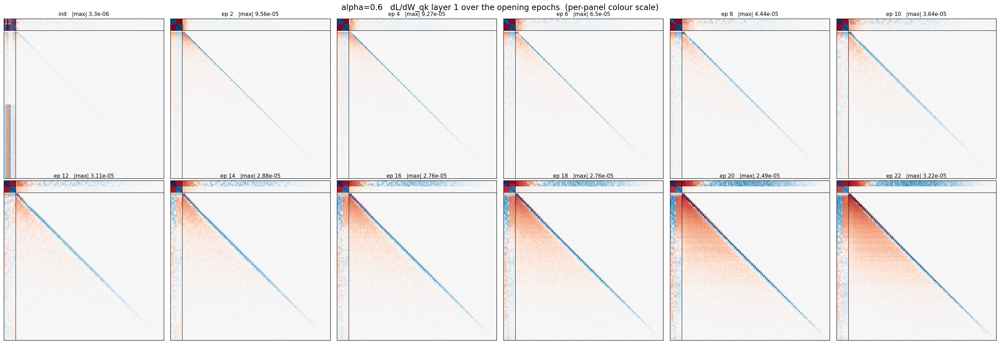

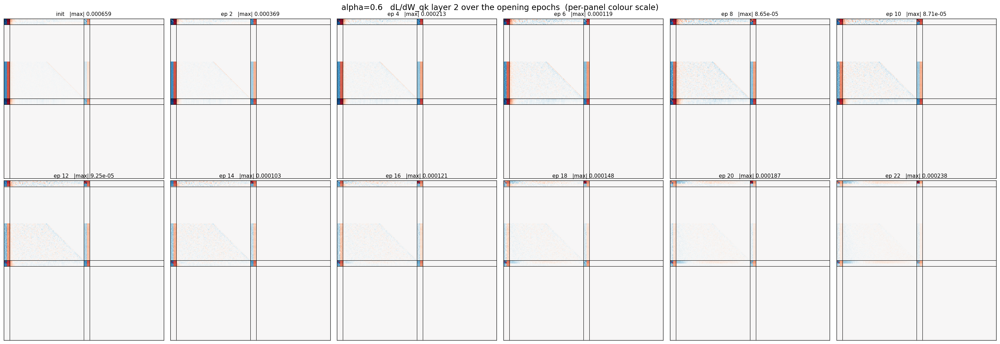

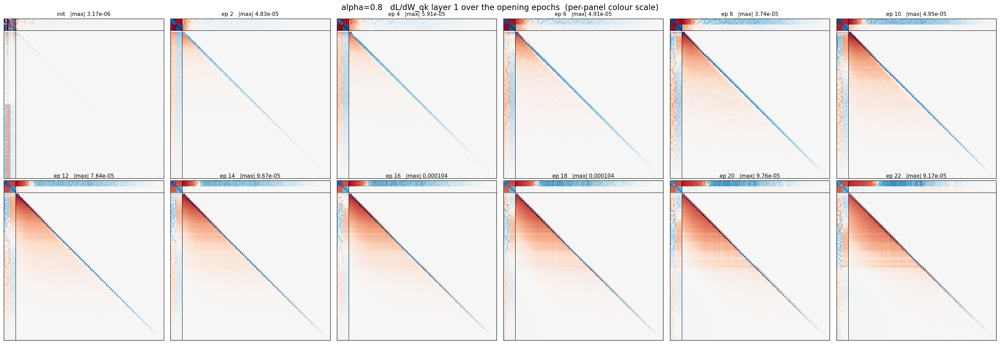

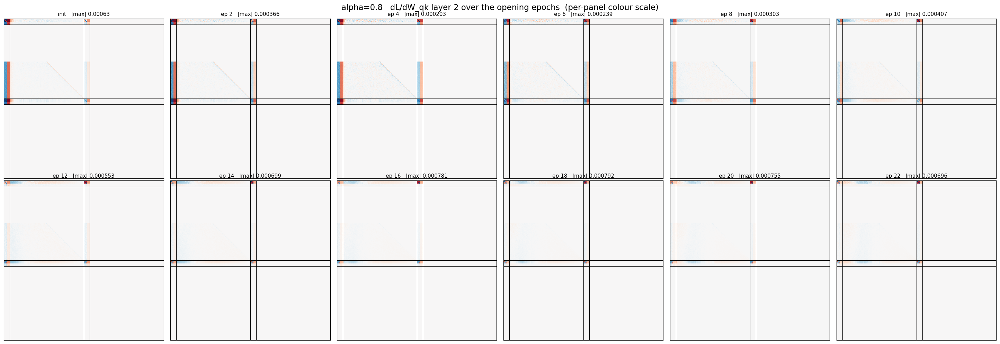

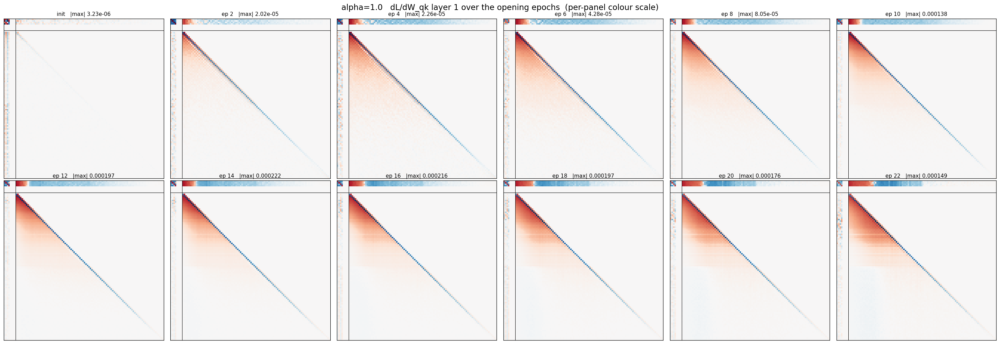

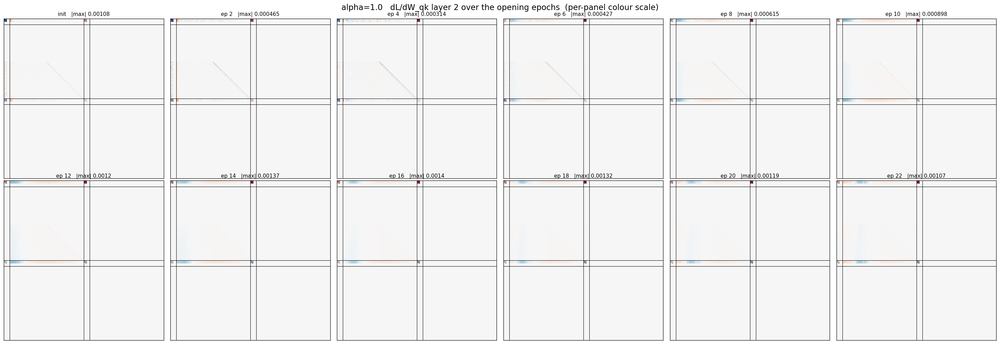

In [16]:
# gradient stills over the opening epochs, same layout as section 8's grid
for t in THRS:
    idx = list(range(0, min(GRID_N * GRID_STEP, GRAD[t][0].shape[0]), GRID_STEP))
    for li, (nm, blocks) in enumerate([('dL/dW_qk layer 1', [V]),
                                       ('dL/dW_qk layer 2', [V, D, D + V])]):
        A = np.asarray(GRAD[t][li][idx], dtype=np.float32)
        ncol = 6
        nrow = int(np.ceil(len(idx) / ncol))
        fig, axes = plt.subplots(nrow, ncol, figsize=(4.4 * ncol, 4.6 * nrow))
        flat = np.atleast_1d(axes).ravel()
        for k in range(len(idx)):
            ax = flat[k]
            v = float(np.abs(A[k]).max()) or 1e-30
            ax.imshow(A[k], cmap='RdBu_r', interpolation='nearest',
                      norm=SymLogNorm(linthresh=v / 100, linscale=0.6, vmin=-v, vmax=v, base=10))
            for b in blocks:
                ax.axhline(b - .5, color='k', lw=0.7); ax.axvline(b - .5, color='k', lw=0.7)
            e = GMETA[t]['epochs'][idx[k]]
            ax.set_title(f'{"init" if e == 0 else f"ep {e}"}   |max| {v:.3g}', fontsize=10)
            ax.set_xticks([]); ax.set_yticks([])
        for ax in flat[len(idx):]:
            ax.axis('off')
        fig.suptitle(f'alpha={t}   {nm} over the opening epochs  (per-panel colour scale)',
                     fontsize=15)
        fig.tight_layout()
        fig.savefig(os.path.join(FIGDIR, f'init_grid_grad{li + 1}_a{t}.png'),
                    bbox_inches='tight')
        plt.show()

## 9.3 The whole run, strided

The counterpart of section 7 for the gradients: the full 1000 epochs at `GRAD_ANIM_STRIDE`, with
$\|g\|$ tracked underneath so the shrinking magnitude is visible alongside the changing pattern.

In [17]:
GRAD_ANIM_THR    = 0.8
GRAD_ANIM_STRIDE = 5
GRAD_ANIM_FPS    = 20

t = GRAD_ANIM_THR
eps_all = GMETA[t]['epochs']
idx = list(range(0, GRAD[t][0].shape[0], GRAD_ANIM_STRIDE))
if idx[-1] != GRAD[t][0].shape[0] - 1:
    idx.append(GRAD[t][0].shape[0] - 1)
gn = {li: np.linalg.norm(np.asarray(GRAD[t][li], dtype=np.float32).reshape(
         GRAD[t][li].shape[0], -1), axis=1) for li in (0, 1)}

fig = plt.figure(figsize=(20, 8.6))
gs = fig.add_gridspec(2, 2, height_ratios=[3, 1])
gx1, gx2 = fig.add_subplot(gs[0, 0]), fig.add_subplot(gs[0, 1])
gx3 = fig.add_subplot(gs[1, :])

def gdraw(fi):
    k = idx[fi]; e = eps_all[k]
    for ax, A, ttl, bl in ((gx1, np.asarray(GRAD[t][0][k]), 'dL/dW_qk layer 1', [V]),
                           (gx2, np.asarray(GRAD[t][1][k]), 'dL/dW_qk layer 2', [V, D, D + V])):
        ax.clear()
        v = float(np.abs(A).max()) or 1e-30
        ax.imshow(A, cmap='RdBu_r', interpolation='nearest',
                  norm=SymLogNorm(linthresh=v / 100, linscale=0.6, vmin=-v, vmax=v, base=10))
        for b in bl:
            ax.axhline(b - .5, color='k', lw=0.8); ax.axvline(b - .5, color='k', lw=0.8)
        ax.set_xticks([]); ax.set_yticks([])
        ax.set_title(f'{ttl}   |max| {v:.4g}', fontsize=12)
    gx3.clear()
    gx3.plot(eps_all, gn[0], color='#1f77b4', lw=1.2, label='||g|| layer 1')
    gx3.plot(eps_all, gn[1], color='#d62728', lw=1.2, label='||g|| layer 2')
    gx3.axvline(e, color='k', lw=1.0)
    gx3.set_yscale('log'); gx3.set_xlabel('epoch  (0 = random init)')
    gx3.grid(alpha=0.25); gx3.legend(fontsize=9, loc='upper right')
    fig.suptitle(f'alpha={t}   gradient field, epoch {e}'
                 f'{"  (random initialization)" if e == 0 else ""}', fontsize=15)

anim = animation.FuncAnimation(fig, gdraw, frames=len(idx),
                               interval=1000 // GRAD_ANIM_FPS, blit=False)
out = os.path.join(FIGDIR, f'grad_evolution_a{t}.mp4')
try:
    anim.save(out, writer=animation.FFMpegWriter(fps=GRAD_ANIM_FPS, bitrate=4000), dpi=110)
except Exception as err:
    print(f'ffmpeg unavailable ({type(err).__name__}: {err}) -- gif instead')
    out = out.replace('.mp4', '.gif')
    anim.save(out, writer=animation.PillowWriter(fps=GRAD_ANIM_FPS), dpi=110)
plt.close(fig)
print(f'{len(idx)} frames -> {out}')
display(Video(out, embed=True, width=1200) if out.endswith('.mp4') else Image(out))

201 frames -> artifacts/figures/grad_evolution_a0.8.mp4


## 10. What to look for

* **Amplitude vs ordering.** Compare $\|W_{qk}\|_F$ in section 1's table against the
  construction's. GD stays orders of magnitude below it and never reaches the $-10^9$
  suppression terms — only the softmax's *ordering* matters, so a low-amplitude matrix with the
  same ranking behaves identically.
* **When the induction block appears.** Section 5's `induction_diag_off` and section 6's
  filmstrip say whether the $4\times4$ diagonal emerges gradually or snaps into place, and
  whether it coincides with the drop in CE.
* **Layer 1 vs layer 2.** The distance-from-init curves in section 6 say which circuit moves
  first. The construction needs layer 1 (previous-token) to work before layer 2's match means
  anything, so a lag there is the mechanism forming in order.
* **$\alpha$ dependence.** At $\alpha=1.0$ there is no noise, so the noise-kill and noise-filter
  terms of the construction are unnecessary; the final matrices should be visibly simpler than at
  $\alpha=0.6$.

* **The opening window.** Section 8 answers whether the structure is there from the first
  epoch or has to be built: on a fixed colour scale, watch whether the picture stays uniform
  noise for a while and then a pattern lifts out, or whether the noise-key stripe and the
  induction diagonal are already visible by epoch 1.
* **Gradient vs update.** Section 9.1 separates what the loss surface asks for from what Adam
  actually applies. A gradient that collapses while the step size stays flat means the run is
  being carried by Adam's normalization, not by a strong signal.
